# 03 – Results analysis
Recomputes headline statistics directly from the raw result JSON files (not the cached tables) as an independent check of `generate_report.py`.

In [1]:
import sys; sys.path.insert(0,'../src')
import json, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
from scipy import stats
R='../reports/experiment-results'
def final(exp, variant):
    out={}
    for f in glob.glob(f'{R}/{exp}/{variant}__seed*.json'):
        r=json.load(open(f)); out[r['seed']]=r['summary']['final']['test_accuracy']
    return pd.Series(out).sort_index()

In [2]:
iid, dr = final('EXP-01','iid'), final('EXP-01','dirichlet0.5')
d = iid - dr
t = stats.ttest_rel(iid, dr)
print(f'IID {iid.mean():.4f}±{iid.std(ddof=1):.4f}  Dir0.5 {dr.mean():.4f}±{dr.std(ddof=1):.4f}')
print(f'paired diff {d.mean():.4f}, p={t.pvalue:.4f}, d_z={d.mean()/d.std(ddof=1):.2f}, n={len(d)}')

IID 0.8668±0.0099  Dir0.5 0.8604±0.0091
paired diff 0.0065, p=0.0748, d_z=1.07, n=5


In [3]:
rows=[]
for a in ['alpha0.1','alpha0.5','alpha1','alpha10']:
    x,y=final('EXP-02',f'{a}__fedprox'),final('EXP-02',f'{a}__fedavg')
    rows.append((a,len(x),x.mean(),y.mean(),(x-y).mean(),stats.ttest_rel(x,y).pvalue))
pd.DataFrame(rows,columns=['alpha','n','fedprox','fedavg','diff','raw_p'])

,alpha,n,fedprox,fedavg,diff,raw_p
0,alpha0.1,8,0.838200,0.821225,0.016975,0.033469
1,alpha0.5,8,0.862775,0.860250,0.002525,0.059351
2,alpha1,8,0.864075,0.862725,0.001350,0.160121
3,alpha10,8,0.866225,0.867150,-0.000925,0.161856


Raw p-values are *before* Holm correction; after correction none of the final-accuracy differences is significant (see the report).

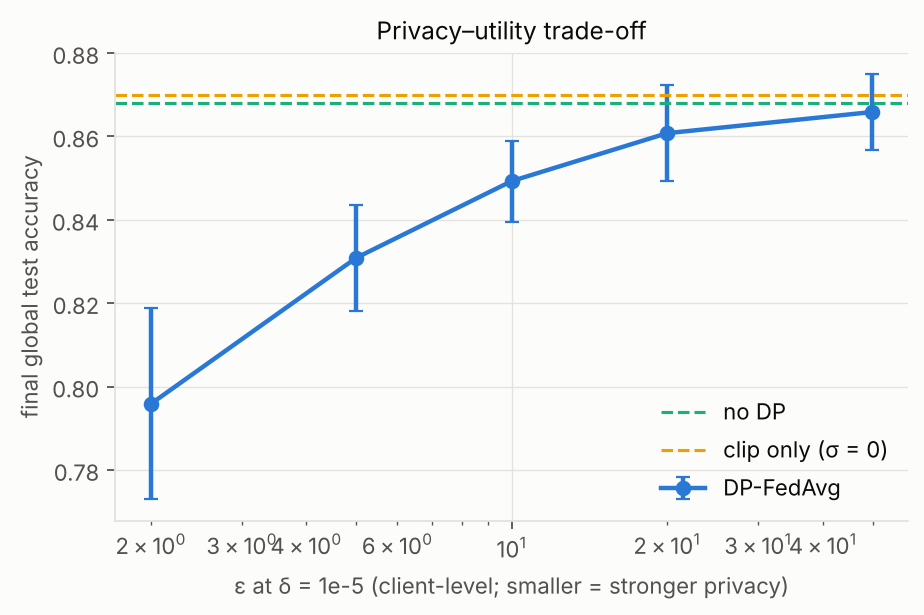

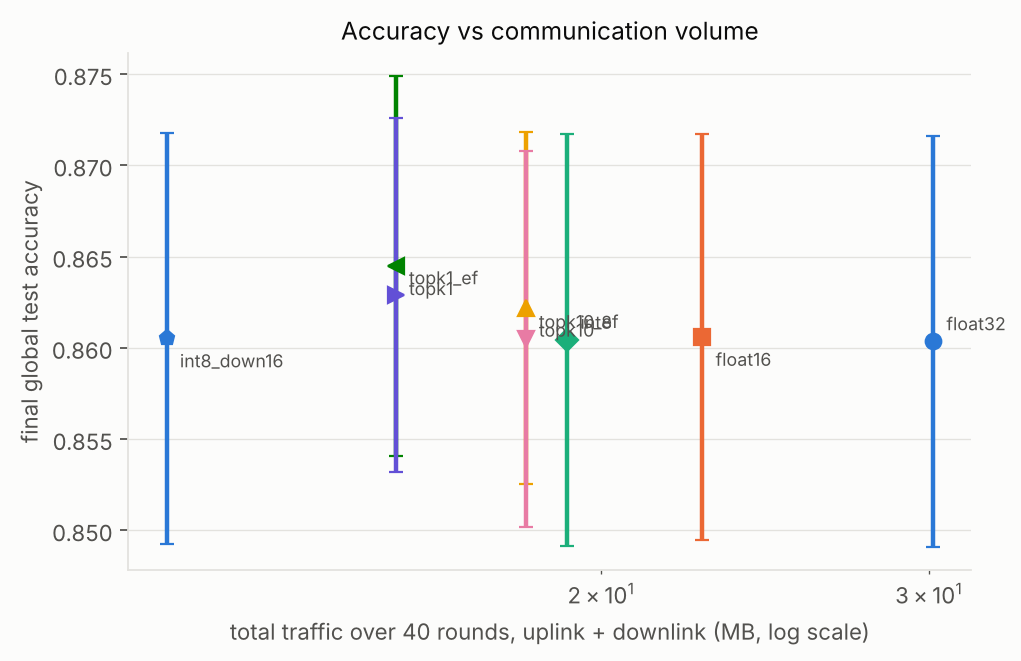

In [4]:
from IPython.display import Image, display
for f in ['exp04_privacy_utility','exp06_compression_tradeoff']:
    display(Image(f'../reports/figures/experiments/{f}.png', width=640))

*Top: accuracy vs ε for client-level DP. Bottom: accuracy vs total measured traffic for each compression scheme.*